In [1]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#  task 1  question:
# Question: Explain why NumPy vectorisation is a technically superior approach to the for-loop
# suggestion. In your answer, describe what broadcasting allows when a single scalar fee rate
# (e.g., Rs 5 per km) is applied to the entire array, and identify one scenario where a Python loop
# would still be necessary despite NumPy being available.


# Answer:
# NumPy vectorisation is technically superior because it performs operations on entire arrays
# without requiring an explicit Python for loop. It is generally faster, uses efficient numerical
#  operations, and produces concise, readable code.

# Broadcasting allows the scalar fee rate of Rs 5
# to be applied to every element of the NumPy array.
# A Python loop may be necessary when each calculation
# depends on the result of the previous iteration.

import numpy as np

distances = np.array([2.0, 5.0, 8.0])
fees = 5 * distances
print(fees)

[10. 25. 40.]


In [7]:
# #    task 2  question:
# # question: Explain why groupby() combined with agg() is the correct approach instead of the
# # for-loop strategy. Describe the specific method chain you would write to compute average order
# # value, average delivery time, and average rating per restaurant in a single operation, and
# # explain what the resulting DataFrame's index represents after the operation

# **Answer:**

# The Pandas `groupby()` method combined with `agg()` is more efficient and readable than using a
# `for` loop because it groups the data by restaurant and calculates multiple summary statistics in a
# single operation. It reduces repetitive code and makes the analysis easier to maintain.

# The following method chain calculates the average order value, average delivery time, and 
# average rating for each restaurant:
# python
# Section A - Question 2: Pandas groupby() and agg()

# Question:
# Explain why groupby() combined with agg() is better than a
# for-loop. Calculate average order value, delivery time, and
# rating per restaurant, and explain the resulting DataFrame index.

# Answer:
# groupby() and agg() are more efficient and readable than
# manually looping through each restaurant. They calculate
# multiple summary statistics in a single operation.
#
# The resulting DataFrame index represents the unique restaurant
# names, with each row showing the restaurant's average values.

import pandas as pd

# Sample dataset
df = pd.DataFrame({
    "restaurant_name": ["A", "B", "A", "C", "B"],
    "order_value": [200, 350, 300, 250, 400],
    "delivery_time_mins": [25, 30, 35, 28, 32],
    "rating": [4.5, 4.0, 4.8, 3.9, 4.2]
})

# Group and calculate averages
summary = df.groupby("restaurant_name").agg(
    mean_order_value=("order_value", "mean"),
    mean_delivery_time=("delivery_time_mins", "mean"),
    mean_rating=("rating", "mean")
)

print(summary)

# Here, `groupby("restaurant_name")` groups rows belonging to the same restaurant, 
# while `agg()` calculates the mean of the three specified columns.

# The resulting DataFrame's index represents the unique restaurant names. 
# Each row contains the average order value, average delivery time, and average rating for that
# restaurant.

                 mean_order_value  mean_delivery_time  mean_rating
restaurant_name                                                   
A                           250.0                30.0         4.65
B                           375.0                31.0         4.10
C                           250.0                28.0         3.90


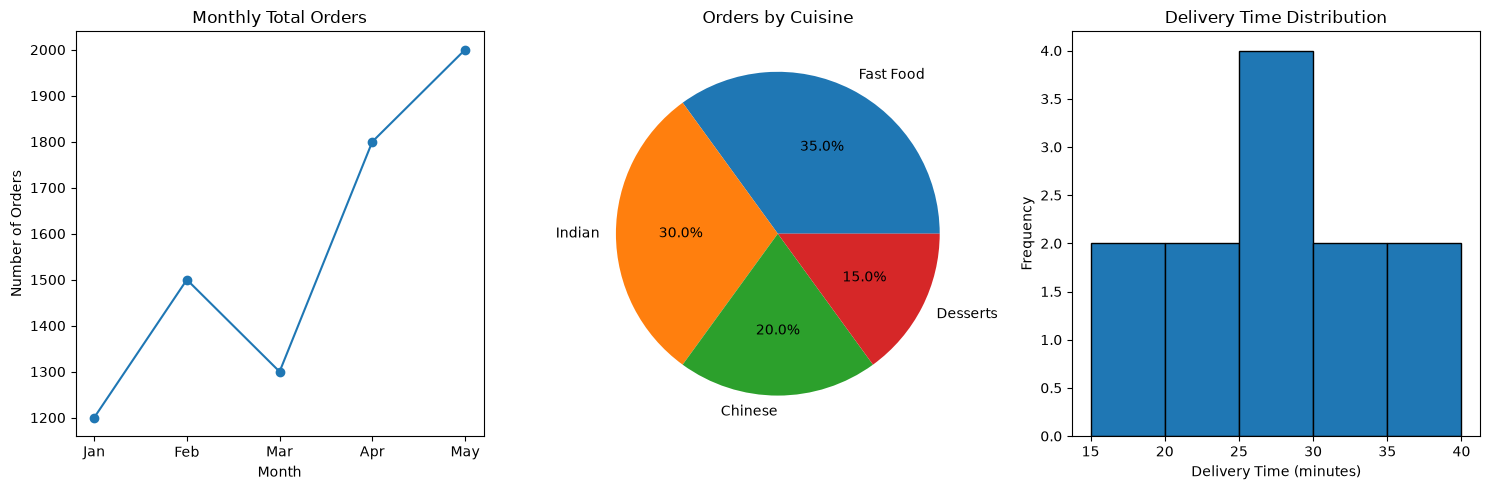

In [ ]:
# task 3

# Question:
# Identify the most appropriate Matplotlib chart type for:
# (a) Monthly total orders
# (b) Proportion of orders by cuisine type
# (c) Distribution of delivery times
# Explain how plt.subplots() arranges the charts and whether
# a shared x-axis is appropriate.

# Answer:
# (a) A line chart is suitable for monthly orders because it
# shows trends and changes over time.
# (b) A pie chart is suitable for showing the proportion of
# orders by cuisine type.
# (c) A histogram is suitable for showing the distribution
# of delivery times.
# plt.subplots() can arrange all three charts side by side
# in one figure using 1 row and 3 columns.
# A shared x-axis is not appropriate because the charts
# represent different types of data.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=False)

# Chart 1: Monthly orders
months = ["Jan", "Feb", "Mar", "Apr", "May"]
orders = [1200, 1500, 1300, 1800, 2000]

axes[0].plot(months, orders, marker="o")
axes[0].set_title("Monthly Total Orders")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Orders")

# Chart 2: Orders by cuisine
cuisines = ["Fast Food", "Indian", "Chinese", "Desserts"]
proportions = [35, 30, 20, 15]

axes[1].pie(proportions, labels=cuisines, autopct="%1.1f%%")
axes[1].set_title("Orders by Cuisine")

# Chart 3: Delivery time distribution
delivery_times = [15, 20, 25, 30, 35, 40, 25, 28, 32, 22, 18, 27]

axes[2].hist(delivery_times, bins=5, edgecolor="black")
axes[2].set_title("Delivery Time Distribution")
axes[2].set_xlabel("Delivery Time (minutes)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

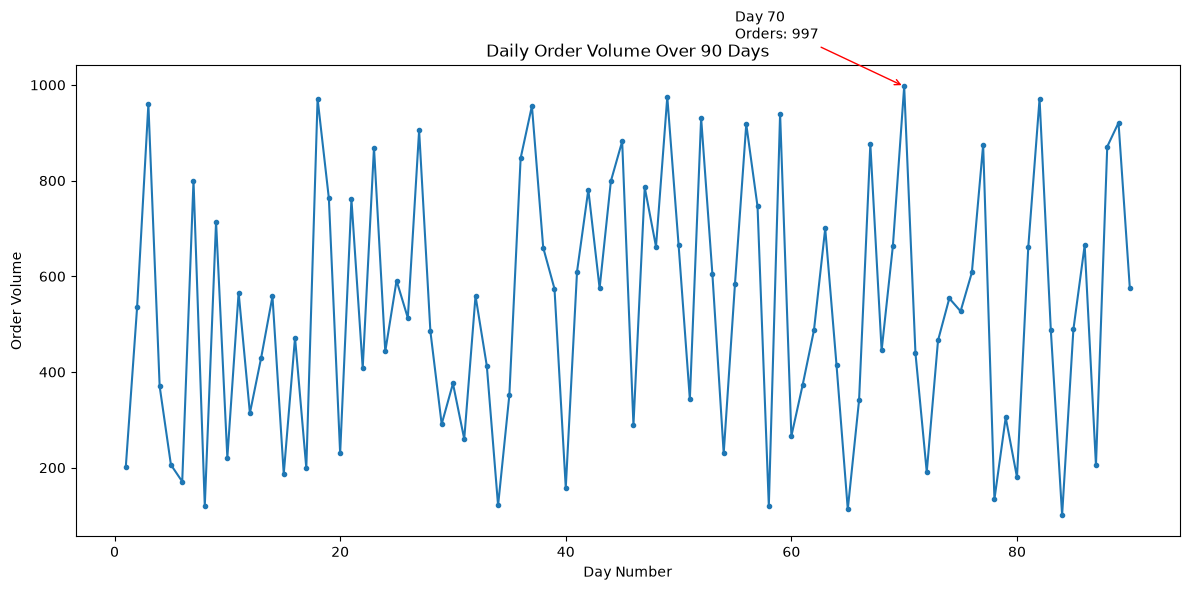

In [9]:
#  task 4 
# Question:
# Explain how plt.annotate() can identify and mark the maximum
# order day with an arrow and a label showing the day number
# and order volume. Explain at least two parameters.

# Answer:
# np.argmax() identifies the index of the maximum order volume.
# xy specifies the point to annotate, while xytext specifies
# the position of the annotation text.
# arrowprops controls the appearance of the arrow.

import numpy as np
import matplotlib.pyplot as plt

days = np.arange(1, 91)
np.random.seed(42)
orders = np.random.randint(100, 1000, size=90)

max_index = np.argmax(orders)
max_day = days[max_index]
max_orders = orders[max_index]

plt.figure(figsize=(12, 6))
plt.plot(days, orders, marker="o", markersize=3)

plt.annotate(
    f"Day {max_day}\nOrders: {max_orders}",
    xy=(max_day, max_orders),
    xytext=(max_day - 15, max_orders + 100),
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=10
)

plt.title("Daily Order Volume Over 90 Days")
plt.xlabel("Day Number")
plt.ylabel("Order Volume")
plt.tight_layout()
plt.show()

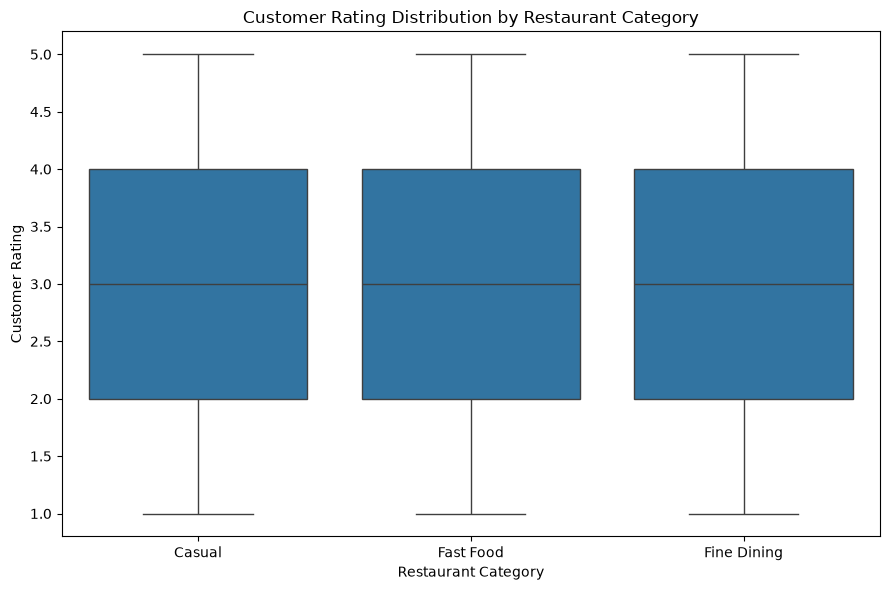

In [10]:
# task 5
# Question:
# Compare sns.boxplot() and sns.violinplot() for customer ratings
# across Fast Food, Fine Dining, and Casual restaurant categories.
# Recommend one chart using at least two dataset-specific reasons
# and explain when the other chart would be preferable.

# Answer:
# I recommend sns.boxplot() because the dataset contains 10,000
# rows across three categories, making it useful for comparing
# medians, quartiles, spread, and potential outliers.
# Ratings use a discrete 1–5 scale, so a boxplot provides a
# straightforward comparison of rating distributions and outliers.
# A violin plot would be preferable when the goal is to examine
# the shape and density of a distribution, especially for continuous
# data with multiple peaks.

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

df = pd.DataFrame({
    "restaurant_category": np.random.choice(
        ["Fast Food", "Fine Dining", "Casual"], size=10000
    ),
    "rating": np.random.randint(1, 6, size=10000)
})

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="restaurant_category",
    y="rating"
)

plt.title("Customer Rating Distribution by Restaurant Category")
plt.xlabel("Restaurant Category")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()

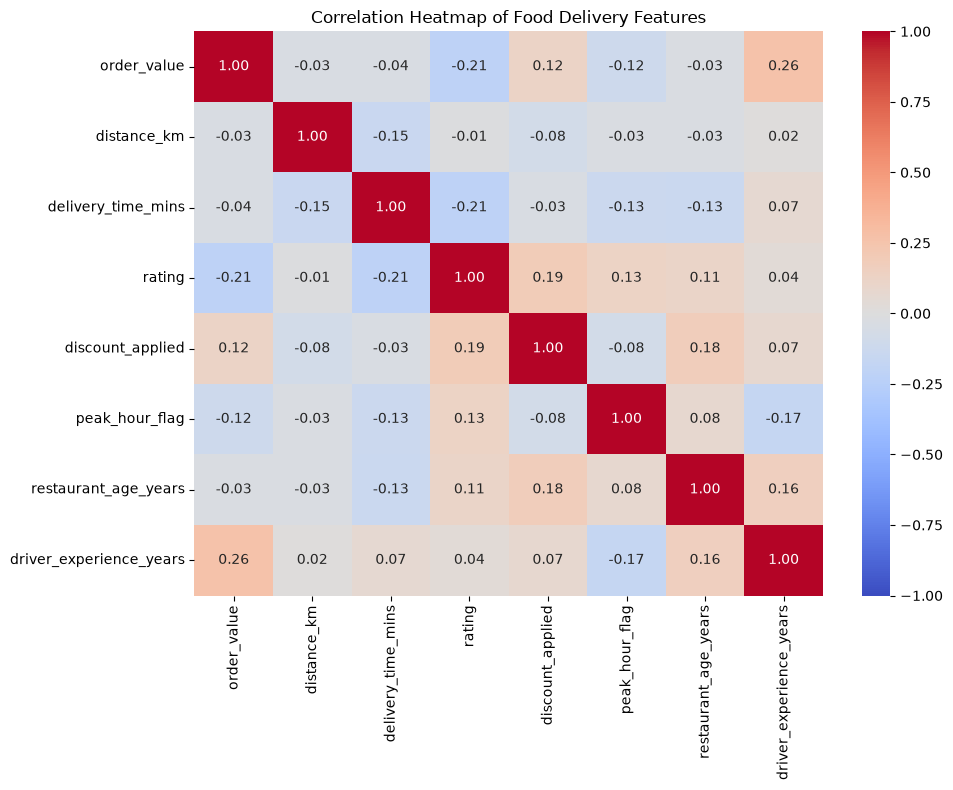

In [11]:
# task 6
# Question:
# Explain how to generate and interpret a Seaborn correlation
# heatmap to identify multicollinearity risks among eight numeric
# features. Explain the colour scale, how to read a cell value,
# and the correlation threshold used to flag potential multicollinearity.

# Answer:
# A correlation heatmap can be generated using the Pearson
# correlation matrix and sns.heatmap().
# The colour scale represents the strength and direction of
# correlations: positive values indicate a positive relationship,
# negative values indicate an inverse relationship, and values
# near zero indicate little or no linear relationship.
# Each cell shows the correlation coefficient between two features.
# A common threshold for potential multicollinearity is an absolute
# correlation greater than 0.8. This threshold is a useful rule
# of thumb for identifying strong relationships between features.

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

df = pd.DataFrame({
    "order_value": np.random.uniform(100, 1000, 100),
    "distance_km": np.random.uniform(1, 20, 100),
    "delivery_time_mins": np.random.uniform(10, 60, 100),
    "rating": np.random.uniform(1, 5, 100),
    "discount_applied": np.random.uniform(0, 50, 100),
    "peak_hour_flag": np.random.randint(0, 2, 100),
    "restaurant_age_years": np.random.uniform(1, 20, 100),
    "driver_experience_years": np.random.uniform(1, 15, 100)
})

correlation_matrix = df.corr(method="pearson")

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Food Delivery Features")
plt.tight_layout()
plt.show()